<img src='https://github.com/wekeo/ai4EM_MOOC/raw/04147f290cfdcce341f819eab7ad037b95f25600/img/ai4eo_logos.jpg' alt='Logo EU Copernicus WEkEO' align='center' width='100%'></img>


### WEkEO TRAINING


***
<center><h1> Monitoring Ecosystem Health in Nepal: From Glacier Collapse to Flood Risk </h1></center>

***
**General Note 1**: Execute each cell through the <button class="btn btn-default btn-xs"><i class="icon-play fa fa-play"></i></button> button from the top MENU (or keyboard shortcut `Shift` + `Enter`).<br>
<br>
**General Note 2**: If, for any reason, the kernel is not working anymore, in the top MENU, click on the <button class="btn btn-default btn-xs"><i class="fa fa-repeat icon-repeat"></i></button> button.<br>


***

# Table of contents
- [1. Introduction](#1.-Introduction)
- [2. Setting up the R environment](#2.-Setting-up-the-R-environment)
- [3. Data Download](#3.-Data-Download)
    - [3.1. Presentation of the product used](#3.1.-Presentation-of-the-product-used)
    - [3.2. Downloading the product](#3.2.-Downloading-the-product)
- [4. Visualising the Flood with Sentinel 2 data](#4.-Visualising-the-Flood-with-Sentinel-2-data)
- [5. Impact of Temperature](#5.-Impact-of-Temperature)
    - [5.1. Exploring the dataset](#5.1.-Exploring-the-dataset)
    - [5.2. Monthly climatologies and anomalies](#5.2.-Monthly-climatologies-and-anomalies)
        - [5.2.1. Monthly climatologies](#5.2.1.-Monthly-climatologies)
        - [5.2.2. Monthly anomaly maps with 2026](#5.2.2.-Monthly-anomaly-maps-with-2026)
    - [5.3. Temperature anomaly at glacier point](#5.3.-Temperature-anomaly-at-glacier-point)
- [6. Exercises](#6.-Exercises)
- [7. Conclusion](#7.-Conclusion)


# 1. Introduction

[Go back to the "Table of contents"](#Table-of-contents)

Mountain ecosystems are highly sensitive to climate and environmental changes. In the Himalayas, rising temperatures are contributing to the retreat and destabilisation of glaciers, increasing the risk of glacier-related hazards such as glacial lake outburst floods (GLOFs). These sudden events can release large volumes of water downstream, causing severe flooding and rapidly changing river and landscape conditions.

The impacts of such events extend beyond immediate damage to infrastructure and human settlements. Floods can alter river systems, damage habitats, affect water quality, transport large amounts of sediment, and disrupt terrestrial and aquatic ecosystems. Understanding these changes is therefore an important part of assessing and monitoring ecosystem health.

Earth Observation provides valuable information for monitoring these rapidly changing environments. Satellite observations can be used to track glacier and land-surface changes, map flooded areas, monitor water bodies and vegetation, and assess environmental conditions before and after an extreme event.

This case study focuses on the flash flood and debris avalanche triggered by a glacier collapse in Nepal on 26 August 2026, exploring its environmental impacts and how Earth Observation data can be used to assess changes in ecosystem health before and after the event.

<center>
    <img src="./img/flooding.PNG" width="600">
</center>

# 2. Setting up the R environment
[Go back to the "Table of contents"](#Table-of-contents)

The Jupyter Notebook must be set up with all the necessary available tools from the Jupyter Notebook ecosystem. Here is the list of the modules we will be using in this exercise.

| Module name | Description |
| :---: | :---|
| **ggplot2** |[ggplot2](https://ggplot2.tidyverse.org/) is a system for declaratively creating graphics. |
| **dplyr** |[dplyr](https://dplyr.tidyverse.org/) is a library for manipulating data. |
| **ncdf4** |[ncdf4](https://cran.r-project.org/web/packages/ncdf4/index.html) is an interface for the 'NetCDF' file formats. |
| **gridExtra** |[gridExtra](https://cran.r-project.org/web/packages/gridExtra/index.html) is a library for arranging multiple grid-based plots on a page. |
| **lubridate** |[lubridate](https://www.rdocumentation.org/packages/lubridate/versions/1.9.3) is a library for fast and user-friendly analysis of date-time data. |
|**rnaturalearth & rnaturalearthdata**|[rnaturalearth](https://cran.r-project.org/web/packages/rnaturalearth/vignettes/rnaturalearth.html) is a data package designed to provide map data. |
|**sf**|[sf](https://cran.r-project.org/web/packages/sf/index.html) is a package for standardized way to encode and analyze spatial vector data. |
|**hdar**|[hdar](https://cran.r-project.org/web/packages/hdar/index.html) is an R package providing a standardized way to access and download data from WEkEO data store. |
|**terra**|[terra](https://rspatial.github.io/terra/)  is used to read, process, analyze, and visualize raster data.


In [1]:
# Modules system
# for ignoring Warning message
options(warn = -1) 

## Load Packages
suppressPackageStartupMessages({ 
    Sys.setenv(
  GDAL_DRIVER_PATH = "/opt/conda/envs/arctic/lib/gdalplugins",
  GDAL_DATA = "/opt/conda/envs/arctic/share/gdal")

    library(terra)            # to read, process and analyse raster data
    library(ggplot2)          # Create graphics and maps
    library(dplyr)            # Data manipulation and transformation
    library(gridExtra)        # Arrange multiple plots on a page
    library(lubridate)        # Work with dates and times
    library(sf)               # Handle and manipulate spatial vector data
    library(rnaturalearth)    # Access Natural Earth geographical data
    library(rnaturalearthdata)# Provides Natural Earth map datasets
    library(hdar)             # To access and download data from the WEkEO
    library(ncdf4)          # High-level interface to netCDF data files 
    
})



code for methods in class “Rcpp_SpatCategories” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatCategories” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatDataFrame” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatDataFrame” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatExtent” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatExtent” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatFactor” was not checked for suspicious field assignments (recommended package ‘codetools’ no

If the required R libraries are not installed, you can use the following command to install them:

<center><h4> install.packages(c("ggplot2", "dplyr", "ncdf4", "gridExtra", "lubridate", "rnaturalearth","rnaturalearthdata","sf","hdar","terra")) </h4></center>

# 3. Data Download

[Go back to the "Table of contents"](#Table-of-contents)

## 3.1. Presentation of the product used

[Go back to the "Table of contents"](#Table-of-contents)


From WEkEO [Data Viewer](https://data.wekeo.copernicus.eu/data?view=viewer&objects=W10%3D&zoom=0), you can explore all the products available with many filters to select the region you are interested in, the parameters you want to study, etc.

In this notebook, we are going to mainly use different datasets:
    
- [ERA5 monthly averaged data on single levels](https://data.wekeo.copernicus.eu/data?view=dataset&dataset=EO:ECMWF:DAT:REANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS) product from ECMWF. It originates from a computer model that simulates atmosphere, ocean and land all around the world. By blending the laws of physics with real-world data from satellites and sensors, it generates accurate monthly updates on ice, temperature ...
- [SENTINEL-2](https://data.wekeo.copernicus.eu/data?view=dataset&dataset=EO%3AESA%3ADAT%3ASENTINEL-2) is a Copernicus Earth Observation mission providing high-resolution optical satellite imagery of the Earth's land and coastal areas. Its data can be used to monitor vegetation, water bodies, glaciers, land cover and changes caused by natural hazards such as floods.


From these products, we retrieve different variables.


| Parameter | Value |
| :---: | :---|
| **Variables used** | temperature |
| **Product identifier** |[EO:ECMWF:DAT:REANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS](https://data.wekeo.copernicus.eu/data?view=dataset&dataset=EO%3AECMWF%3ADAT%3AREANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS) |
| **Temporal resolution** | Monthly |
| **Spatial resolution** | 25 × 25 km |
| **Temporal coverage** | January 2000 to August 2026 |


<center>
    <img src="./img/ERA5_image.PNG" width="200">
</center>

----

| Parameter | Value |
| :---: | :---|
| **Variables used** | Optical image |
| **Product identifier** |[SENTINEL-2](https://data.wekeo.copernicus.eu/data?view=dataset&dataset=EO%3AESA%3ADAT%3ASENTINEL-2) |
| **Temporal resolution** | 5 days nominal revisit |
| **Spatial resolution** | 10, 20 or 60m |
| **Temporal coverage** | 12 and 27 August 2026 |


<center>
    <img src="./img/sentinel2.PNG" width="400">
</center>

## 3.2. Downloading the product

[Go back to the "Table of contents"](#Table-of-contents)

First, we define the username and password:

In [10]:
username <- "username"
password <-"password"

client <- Client$new(
    username,password,
    save_credentials = TRUE
)

Once the credentials are saved, you can initialize the Client without passing the credentials. 

In [11]:
client <- Client$new()

The query is specific, it should be a JSON string that defines the parameters for the data search, including dataset ID, product type, variables, date, etc. To see the available query parameters, run the following command with the dataset ID:

In [13]:
client$generate_query_template("EO:ECMWF:DAT:REANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS")

{
  "dataset_id": "EO:ECMWF:DAT:REANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS",
  "product_type": ["monthly_averaged_reanalysis", "monthly_averaged_reanalysis_by_hour_of_day", "monthly_averaged_ensemble_members", "monthly_averaged_ensemble_members_by_hour_of_day"],
  "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind", "2m_dewpoint_temperature", "2m_temperature", "mean_sea_level_pressure", "mean_wave_direction", "mean_wave_period", "sea_surface_temperature", "significant_height_of_combined_wind_waves_and_swell", "surface_pressure", "total_precipitation", "2m_dewpoint_temperature", "2m_temperature", "ice_temperature_layer_1", "ice_temperature_layer_2", "ice_temperature_layer_3", "ice_temperature_layer_4", "mean_sea_level_pressure", "sea_surface_temperature", "skin_temperature", "surface_pressure", "100m_u_component_of_wind", "100m_v_component_of_wind", "10m_u_component_of_neutral_wind", "10m_u_component_of_wind", "10m_v_component_of_neutral_wind", "10m_v_component_of_wind", 

The query we need is:

In [14]:
query <- '{
  "dataset_id": "EO:ECMWF:DAT:REANALYSIS_ERA5_SINGLE_LEVELS_MONTHLY_MEANS",
  "product_type": [
    "monthly_averaged_reanalysis"
  ],
  "variable": [
    "2m_temperature"
  ],
  "year": [
    "2000","2001","2002","2003","2004","2005","2006","2007","2008","2009","2010","2011","2012",
    "2013","2014","2015","2016","2017","2018","2019","2020","2021","2022","2023","2024","2025","2026"],
  "month": ["01","02","03","04","05","06","07","08","09","10","11","12"],
  "time": ["00:00"],
  "bbox": [80,22,90,40],
  "data_format": "netcdf",
  "download_format": "unarchived",
  "itemsPerPage": 200,
  "startIndex": 0
}'


In [15]:
# Assuming 'client' is already created and authenticated
matches <- client$search(query)


Found 1 files

Total Size 0 B



Now you define the output directory where the downloaded files will be saved.

In [16]:
# output directory where the downloaded files will be saved
output_directory <- "./data"

# if the output directory does not exist, create it
dir.create(
  output_directory,
  showWarnings = FALSE,
  recursive = TRUE
)

In [17]:
# download the data files to the specified output directory
matches$download(output_directory)


<div class="alert alert-block alert-info">

The Sentinel-2 data have already been downloaded. To save storage space, we will use the data provided in this notebook. The dataset contains a large amount of information, including multiple spectral bands at different spatial resolutions.

For this training, we only need three bands at 10 m resolution: B02 (blue), B03 (green), and B04 (red). These bands are therefore provided directly in the notebook and do not need to be downloaded again.

</div>

# 4. Visualising the Flood with Sentinel 2 data
[Go back to the "Table of contents"](#Table-of-contents)

Sentinel-2 provides high-resolution optical satellite imagery that can be used to monitor changes in the Earth's surface. With a spatial resolution of up to 10 m, Sentinel-2 is particularly useful for observing vegetation, water bodies, land cover and the impacts of natural hazards such as floods.

In this section, we will use Sentinel-2 imagery to visualise the area before and after the flooding event in Nepal. We will compare a satellite image acquired on 12 August 2026, before the event, with an image acquired on 27 August 2026, one day after the disaster. By comparing these two images, we will identify changes in the landscape and observe the extent of the flooded area. This comparison provides a first assessment of the environmental impacts of the event and illustrates how Earth Observation data can support the monitoring of ecosystem health.

In [2]:
# Set the path for the Sentinel-2 images
B02 <- rast("data/12_August_2026/B02_before_event.jp2")
B03 <- rast("data/12_August_2026/B03_before_event.jp2")
B04 <- rast("data/12_August_2026/B04_before_event.jp2")

We define a polygon around the study area using its longitude and latitude coordinates. This allows us to focus the analysis on the area of interest rather than processing the entire Sentinel-2 scene.

By limiting the spatial extent, we can zoom in on the study area and reduce the amount of data to process, making data manipulation and visualisation faster and more efficient.

In [3]:
# Define a matrix of coordinates (longitude, latitude) for the polygon
coords <- matrix(c(
 85.05, 27.85,
  85.05, 29,
  85.2, 29,
  85.2, 27.85,
  85.05, 27.85
), ncol = 2, byrow = TRUE)

In [4]:
# Create a polygon from the coordinates
poly_latlon <- st_polygon(list(coords))

In [5]:
# Convert the polygon into an 'sf' spatial object with WGS84 coordinate reference system
poly_sf <- st_sfc(poly_latlon, crs = 4326)  # WGS84

In [6]:
# Transform the polygon into the same CRS as the raster (UTM)
poly_utm <- st_transform(poly_sf, crs = crs(B04))

In [7]:
# Convert the 'sf' polygon into a terra vector object
poly_vect <- vect(poly_utm)

In [8]:
# Crop each Sentinel-2 band to the area defined by the polygon
b2  <- crop(B02,  poly_vect)  # Blue band
b3  <- crop(B03,  poly_vect)  # Green band
b4  <- crop(B04,  poly_vect)  # Red band

In [9]:
# Combine Red, Green, and Blue bands to create a true-color RGB composite
rgb <- c(b4, b3, b2)

# Assign meaningful names to the layers
names(rgb) <- c("R", "G", "B")

In [10]:
# Perform contrast stretching to enhance visualization
rgb_stretch_before <- stretch(rgb, minq = 0.1, maxq = 0.9)

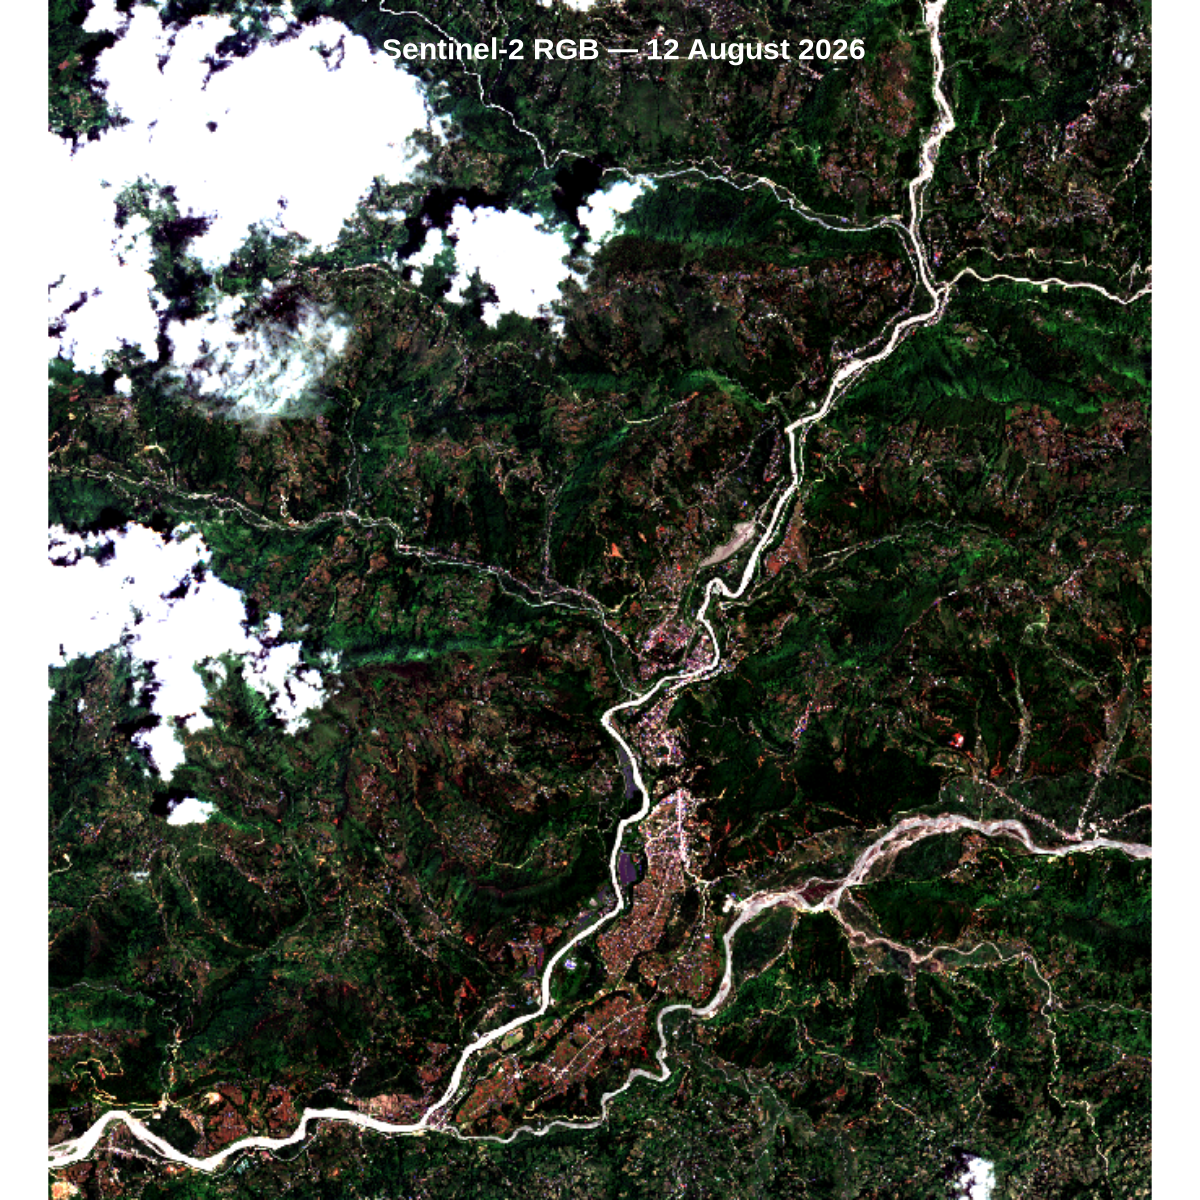

In [11]:
# Determine figure size
options(repr.plot.width =10, repr.plot.height = 10) 

# Plot the RGB image
plotRGB(rgb_stretch_before,
        r = 1, g = 2, b = 3)
title(main = "Sentinel-2 RGB — 12 August 2026", cex.main = 1.5, col.main = "white", font.main = 2)

In this figure, you can see the Trishuli River before the flash flood. The river flows from north to south and has a moderate width. 

Now, let’s look at the same area after the flash flood and see how the landscape has changed.

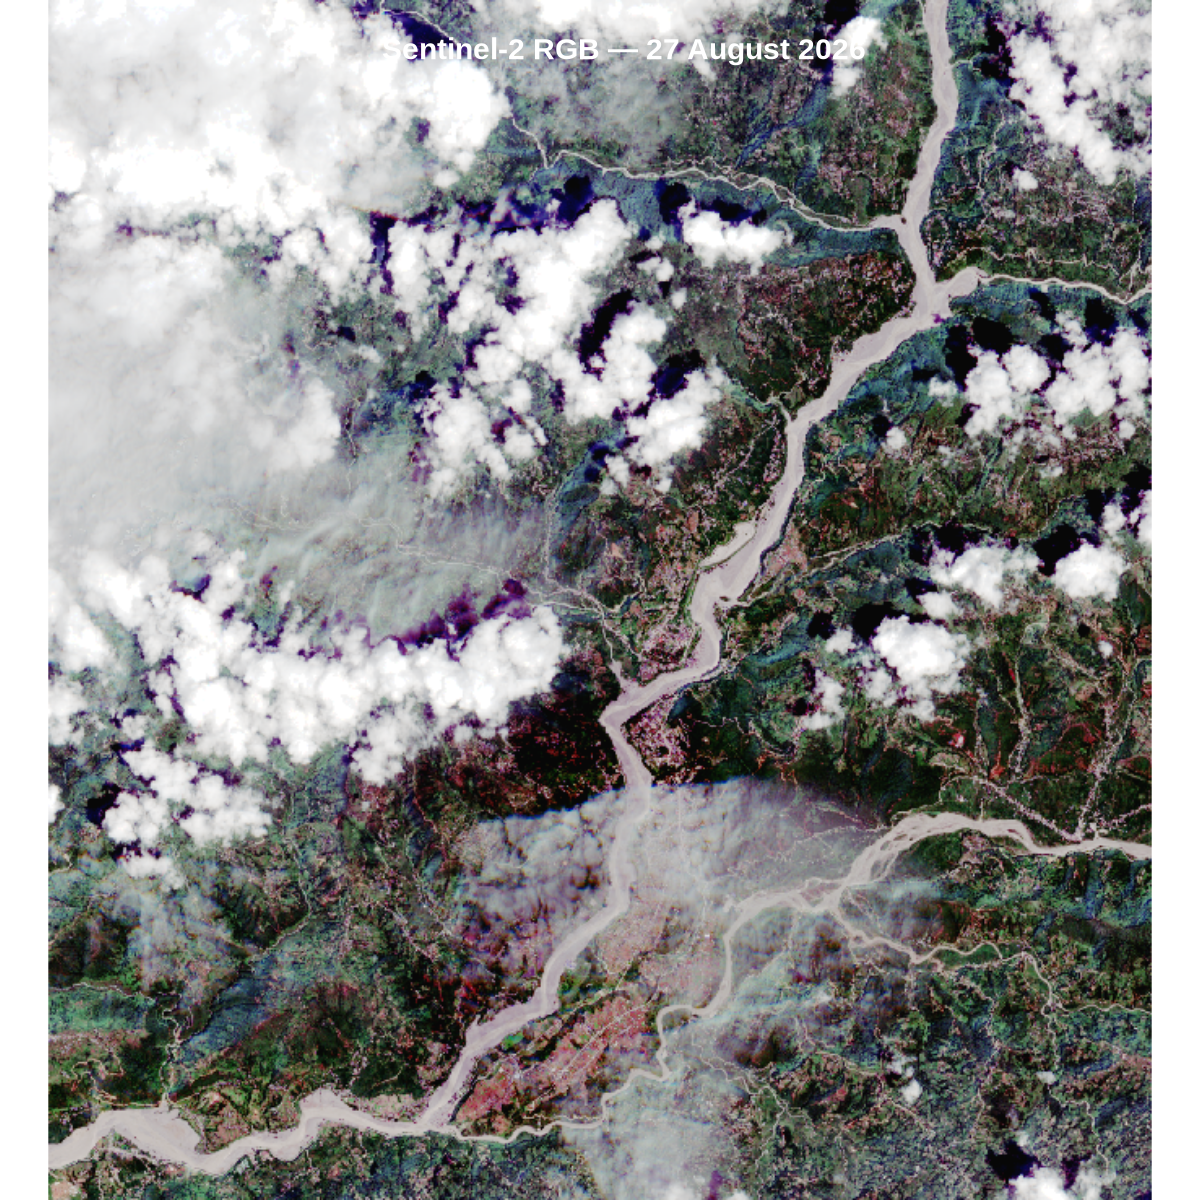

In [12]:
#  Set the path for the Sentinel-2 images
B02 <- rast("data/27_August_2026/B02_after_event.jp2")
B03 <- rast("data/27_August_2026/B03_after_event.jp2")
B04 <- rast("data/27_August_2026/B04_after_event.jp2")

# Define a matrix of coordinates (longitude, latitude) for the polygon
coords <- matrix(c(
 85.05, 27.85,
  85.05, 29,
  85.2, 29,
  85.2, 27.85,
  85.05, 27.85
), ncol = 2, byrow = TRUE)

# Create a polygon from the coordinates
poly_latlon <- st_polygon(list(coords))

# Convert the polygon into an 'sf' spatial object with WGS84 coordinate reference system
poly_sf <- st_sfc(poly_latlon, crs = 4326)  # WGS84

# Transform the polygon into the same CRS as the raster (UTM)
poly_utm <- st_transform(poly_sf, crs = crs(B04))

# Convert the 'sf' polygon into a terra vector object
poly_vect <- vect(poly_utm)

# Crop each Sentinel-2 band to the area defined by the polygon
b2  <- crop(B02,  poly_vect)  # Blue band
b3  <- crop(B03,  poly_vect)  # Green band
b4  <- crop(B04,  poly_vect)  # Red band

# Determine figure size
options(repr.plot.width =10, repr.plot.height = 10 )

# Combine Red, Green, and Blue bands
rgb <- c(b4, b3, b2)
names(rgb) <- c("R", "G", "B")

# Contrast stretching
rgb_stretch_after <- stretch(rgb, minq = 0.03, maxq = 0.97)

# Plot RGB
plotRGB(rgb_stretch_after,
        r = 1,
        g = 2,
        b = 3,
        stretch = "hist")

# Add title
title(main = "Sentinel-2 RGB — 27 August 2026",
      cex.main = 1.5,
      col.main = "white",
      font.main = 2)

The change is significant. The river is much wider after the flood, and we can clearly see a major difference between the two images.

Let’s now look at both images side by side, with a scale bar, to better understand the extent of the flood’s impact on the ecosystem.

In [ ]:
# Determine figure size
options(repr.plot.width = 20, repr.plot.height = 10)

par(mfrow = c(1, 2))


# =========================================================
# Before event
# =========================================================

plotRGB(
  rgb_stretch_before,
  r = 1, g = 2, b = 3,
  stretch = "lin",
  main = "12 August 2026"
)

# Get image extent
e <- ext(rgb_stretch_before)

# Define scale bar position
x0 <- e[1] + 0.05 * (e[2] - e[1])
y0 <- e[3] + 0.10 * (e[4] - e[3])

# Draw white outline
segments(x0, y0, x0 + 5000, y0, col = "white", lwd = 15)
# Draw black scale bar
segments(x0, y0, x0 + 5000, y0, col = "black", lwd = 8)
# Add red label
text(x0 + 2500, y0 + 500, "5 km", col = "red", cex = 2, font = 2)

# =========================================================
# After event
# =========================================================

plotRGB(
  rgb_stretch_after,
  r = 1, g = 2, b = 3,
  stretch = "hist",
  main = "27 August 2026"
)

# Get image extent
e <- ext(rgb_stretch_after)

# Define scale bar position
x0 <- e[1] + 0.05 * (e[2] - e[1])
y0 <- e[3] + 0.10 * (e[4] - e[3])

# Draw white outline
segments(x0, y0, x0 + 5000, y0, col = "white", lwd = 15)
# Draw black scale bar
segments(x0, y0, x0 + 5000, y0, col = "black", lwd = 8)
# Add red label
text(x0 + 2500, y0 + 500, "5 km", col = "red", cex = 2, font = 2)

The image on the right was acquired on 27 August, the day after the event, while the image on the left was captured on 12 August, before the flood. Both images are shown in natural colour. The post-event image clearly shows a dramatic increase in the river's width.

We can observe significant changes in the landscape. Before the event, the areas surrounding the river were mostly green, indicating vegetation-covered land. After the flood, these areas appear much more muddy and brown, suggesting that they were covered by water and sediment.

The shape of the river has also changed considerably. Several meanders visible before the event have disappeared or become much less distinct, while the river channel appears wider and more irregular. New sediment deposits can also be observed along the river and on the surrounding land.

Overall, the comparison shows that the flash flood had a major impact on the river system and the surrounding ecosystem, rapidly transforming both the river channel and the adjacent land.

The disaster was triggered by a glacier collapse. We will now investigate whether rising temperatures associated with climate change may have contributed to the conditions that led to this event.

# 5. Impact of Temperature
[Go back to the "Table of contents"](#Table-of-contents)

In this section, we will investigate temperature conditions around the time of the glacier collapse. Using the temperature data downloaded from Copernicus, we will visualise the temperature evolution and examine whether unusually high temperatures were observed before the event. This will help us explore whether rising temperatures may have contributed to glacier instability.

## 5.1. Exploring the dataset
[Go back to the "Table of contents"](#Table-of-contents)



We have downloaded the needed data. The location of the file is: `data/`. Let's now open it using the **netcdf4** library.

In [32]:
file <- "data/reanalysis-era5-single-levels-monthly-means-f8a342ebf0f9bc082b701bd99edcab69.nc"

In [33]:
# Load NetCDF File
data <- nc_open(file)

In [34]:
# Access Data 
latitude <- ncvar_get(data, "latitude")  # Name of the latitude variable
longitude <- ncvar_get(data, "longitude")  # Name of the longitude variable

time <- ncvar_get(data, "valid_time")  # Name of the time variable
time_values <- as.POSIXct(time, origin = "1970-01-01", tz = "GMT")

t2m<- ncvar_get(data, "t2m")-273.15  # 2-metre air temperature - we do -273.15 to convert from Kelvin to Celsius


In [35]:
# Print time to verify that the time variable has been correctly converted to POSIXct format
time_values[1:10]

 [1] "2000-01-01 GMT" "2000-02-01 GMT" "2000-03-01 GMT" "2000-04-01 GMT"
 [5] "2000-05-01 GMT" "2000-06-01 GMT" "2000-07-01 GMT" "2000-08-01 GMT"
 [9] "2000-09-01 GMT" "2000-10-01 GMT"

We will now proceed to visualize the data using ggplot2. We will create a dataframe over a specified time period.

In [36]:
# we choose a specific time index to extract data for that time step
index_time=5

# we extract the data for the chosen time step
t2m_int=t2m[,,index_time]

# we create a dataframe
df <- data.frame(expand.grid(longitude, latitude, time_values[index_time]), 
                 t2m = as.vector(t2m_int))

names(df) <- c("Longitude", "Latitude","time","t2m")

# visualisation of the dataframe
df[1:10,]

,Longitude,Latitude,time,t2m
,<dbl[1d]>,<dbl[1d]>,<dttm>,<dbl>
1,80.00,40,2000-05-01,24.67593
2,80.25,40,2000-05-01,24.72476
3,80.50,40,2000-05-01,25.05093
4,80.75,40,2000-05-01,25.25991
5,81.00,40,2000-05-01,25.26772
6,81.25,40,2000-05-01,25.31069
7,81.50,40,2000-05-01,25.32632
8,81.75,40,2000-05-01,25.33022
9,82.00,40,2000-05-01,25.33022


In [37]:
# We create the output directory:
dir.create("./figures/", recursive = TRUE, showWarnings = FALSE)

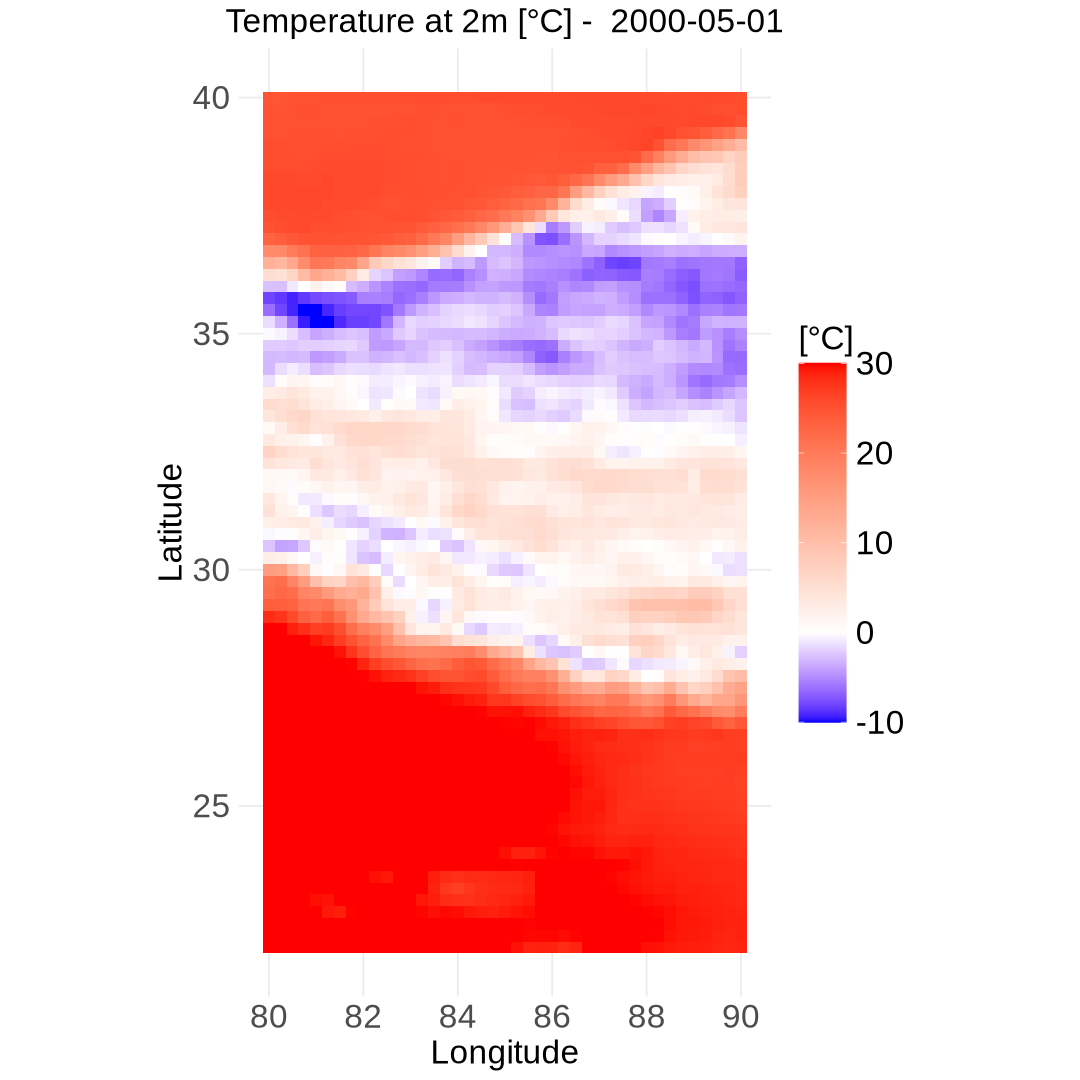

In [38]:
# To define the dimension of the image
options(repr.plot.width = 9, repr.plot.height = 9)

# Plotting
p <- ggplot() +

# Add t2m data 
geom_raster (data = df, aes(x=Longitude, y=Latitude, fill = t2m)) +

# Color scale options limits
scale_fill_gradientn(colors = c("blue", "white", "red"),values = scales::rescale(c(-10, 0, 30)), limits = c(-10,30),oob = scales::squish,name = "[°C]",na.value = "grey") +

# General aesthetic options
theme_light() +

# Title and subtitle
labs(title = paste("Temperature at 2m [°C] -  ",time_values[index_time],sep=''),
     x = "Longitude",
     y = "Latitude")+

# Legend position and aesthetic options
theme_minimal()+

theme(
    axis.text.x = element_text(size = 20),  # Increase the size of the x-axis values
    axis.text.y = element_text(size = 20),  # Increase the size of the y-axis values
    plot.title = element_text(hjust = 0.5, size = 20),  # Center and increase the size of the title
    axis.title.x = element_text(size = 20),  # Increase the size of the x-axis title
    axis.title.y = element_text(size = 20),  # Increase the size of the y-axis title
    legend.text = element_text(size = 20),    # Increase the size of the legend text
    legend.title = element_text(size = 20)     # Increase the size of the legend title
)   +
   coord_sf()+
guides(fill = guide_colorbar(barwidth = 2, barheight = 15)) 

# to save the figure
ggsave("./figures/basic_figure_of_temperature.png", plot = p, width = 12, height = 6, dpi = 300)
    
p

We can see the 2-m air temperature in May 2000. Temperatures range from approximately −10°C to 30°C, with lower temperatures mainly observed in the mountains (center of the image). However, it is difficult to clearly distinguish the country and the area.

To make the map easier to interpret, we will add country borders to clearly distinguish the area. First, we retrieve the country boundaries from the Natural Earth database and make sure that they use the same coordinate reference system (CRS) as our ERA5 data. We then convert the spatial boundaries into coordinates so that they can be added to our ggplot map.

In [39]:
# Retrieve country boundaries from the Natural Earth database
countries <- ne_countries(
  scale = "medium",
  returnclass = "sf"
)

# If the CRS is missing, assign WGS84 (EPSG:4326)
if (is.na(st_crs(countries))) {
  st_crs(countries) <- 4326
}

# Convert the country boundaries from spatial features (sf)
# into a table of coordinates (X, Y)
countries_coords <- st_coordinates(countries)

# Convert the coordinates into a data frame
countries_coords <- as.data.frame(countries_coords)

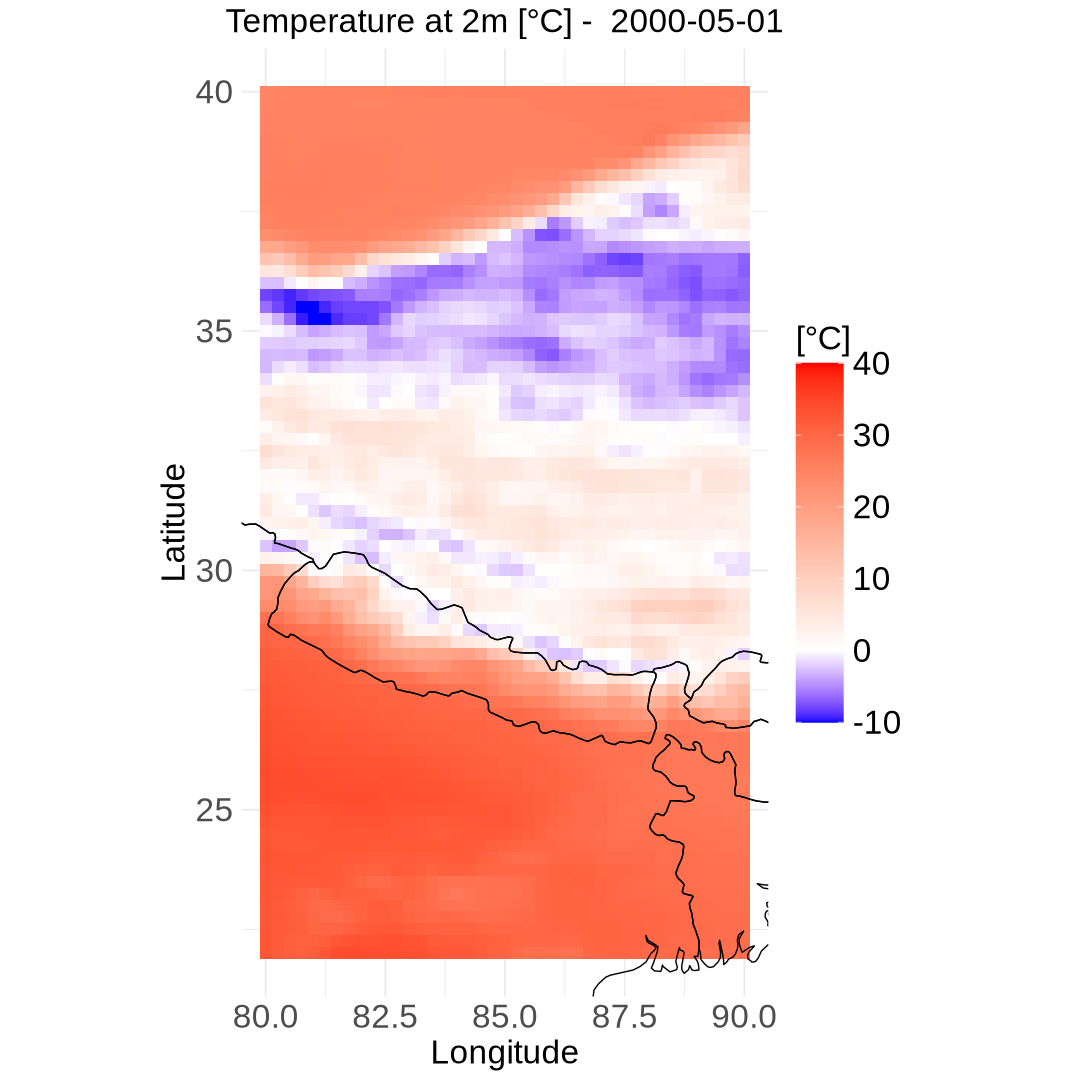

In [40]:
# To define the dimension of the image
options(repr.plot.width = 9, repr.plot.height = 9)

# Plotting
p <- ggplot() +

#  Add t2m data
geom_raster (data = df, aes(x=Longitude, y=Latitude, fill = t2m)) +

# Country borders
geom_path(data = countries_coords,aes(x = X,y = Y,group = interaction(L1, L2, L3)), color = "black",linewidth = 0.4) +

# Limit the map to the extent of df
coord_fixed(xlim = c(min(df$Longitude, na.rm = TRUE),max(df$Longitude, na.rm = TRUE)),
    ylim = c(min(df$Latitude, na.rm = TRUE),max(df$Latitude, na.rm = TRUE))) +

# Color scale options limits
scale_fill_gradientn(colors = c("blue", "white", "red"),values = scales::rescale(c(-10, 0, 40)), limits = c(-10,40),oob = scales::squish,name = "[°C]",na.value = "grey") +

# General aesthetic options
theme_light() +

# Title and subtitle
labs(title = paste("Temperature at 2m [°C] -  ",time_values[index_time],sep=''),
     x = "Longitude",
     y = "Latitude")+

# Legend position and aesthetic options
theme_minimal()+

theme(
    axis.text.x = element_text(size = 20),  # Increase the size of the x-axis values
    axis.text.y = element_text(size = 20),  # Increase the size of the y-axis values
    plot.title = element_text(hjust = 0.5, size = 20),  # Center and increase the size of the title
    axis.title.x = element_text(size = 20),  # Increase the size of the x-axis title
    axis.title.y = element_text(size = 20),  # Increase the size of the y-axis title
    legend.text = element_text(size = 20),    # Increase the size of the legend text
    legend.title = element_text(size = 20)     # Increase the size of the legend title
)   +
  
guides(fill = guide_colorbar(barwidth = 2, barheight = 15)) 
    
p

With the country borders added, the different areas can be identified more clearly.

We will create the same plot, but this time we will add a red point to indicate the location of the glacier collapse.

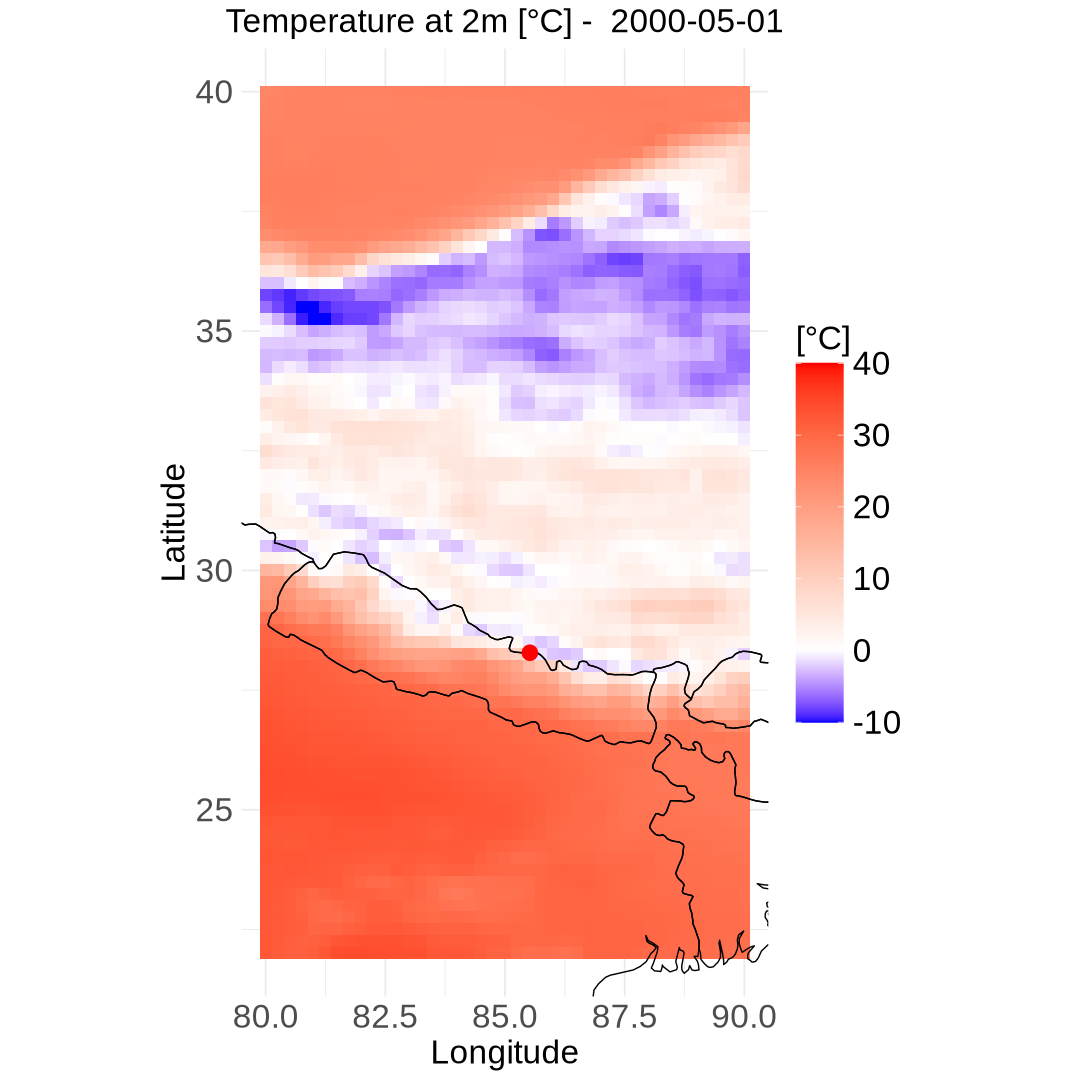

In [41]:
# To define the dimension of the image
options(repr.plot.width = 9, repr.plot.height = 9)

# Plotting
p <- ggplot() +

#  Add t2m data
geom_raster (data = df, aes(x=Longitude, y=Latitude, fill = t2m)) +

# Country borders
geom_path(data = countries_coords,aes(x = X,y = Y,group = interaction(L1, L2, L3)), color = "black",linewidth = 0.4) +

# Limit the map to the extent of df
coord_fixed(xlim = c(min(df$Longitude, na.rm = TRUE),max(df$Longitude, na.rm = TRUE)),
    ylim = c(min(df$Latitude, na.rm = TRUE),max(df$Latitude, na.rm = TRUE))) +

# Color scale options limits
scale_fill_gradientn(colors = c("blue", "white", "red"),values = scales::rescale(c(-10, 0, 40)), limits = c(-10,40),oob = scales::squish,name = "[°C]",na.value = "grey") +

# location of the glacier collapse
annotate("point", x = 85.52, y = 28.28, color = "red", size = 4)    +

# General aesthetic options
theme_light() +

# Title and subtitle
labs(title = paste("Temperature at 2m [°C] -  ",time_values[index_time],sep=''),
     x = "Longitude",
     y = "Latitude")+

# Legend position and aesthetic options
theme_minimal()+

theme(
    axis.text.x = element_text(size = 20),  # Increase the size of the x-axis values
    axis.text.y = element_text(size = 20),  # Increase the size of the y-axis values
    plot.title = element_text(hjust = 0.5, size = 20),  # Center and increase the size of the title
    axis.title.x = element_text(size = 20),  # Increase the size of the x-axis title
    axis.title.y = element_text(size = 20),  # Increase the size of the y-axis title
    legend.text = element_text(size = 20),    # Increase the size of the legend text
    legend.title = element_text(size = 20)     # Increase the size of the legend title
)   +
  
guides(fill = guide_colorbar(barwidth = 2, barheight = 15)) 
    
p

## 5.2. Monthly climatologies and anomalies
[Go back to the "Table of contents"](#Table-of-contents)

In this section, we will analyse the temperature data in more detail by calculating monthly climatologies and anomalies. The climatology will show the typical temperature conditions for each month, while the anomalies will allow us to identify periods when temperatures were unusually high or low compared with these typical conditions. This will help us assess whether the period before the glacier collapse was characterised by unusually warm temperatures.

### 5.2.1. Monthly climatologies
[Go back to the "Table of contents"](#Table-of-contents)

We will examine the monthly climatology of air temperature. To do this, we will calculate the average temperature for each month over the period 2000–2026. For example, all January values will be averaged together to obtain the January climatology, then the same calculation will be performed for February, March, and so on through December. This will allow us to characterize the typical seasonal temperature cycle in the area.

In [42]:
# we create a dataframe
df_climatology <- data.frame(expand.grid(longitude, latitude,time_values), 
                 t2m = as.vector(t2m[,,]))

names(df_climatology) <- c("Longitude", "Latitude","time","t2m")

# print the first 10 rows of the dataframe
df_climatology[1:10,]

,Longitude,Latitude,time,t2m
,<dbl[1d]>,<dbl[1d]>,<dttm[1d]>,<dbl>
1,80.00,40,2000-01-01,-5.286597
2,80.25,40,2000-01-01,-5.450659
3,80.50,40,2000-01-01,-5.677222
4,80.75,40,2000-01-01,-5.882300
5,81.00,40,2000-01-01,-6.075659
6,81.25,40,2000-01-01,-5.954565
7,81.50,40,2000-01-01,-5.858862
8,81.75,40,2000-01-01,-5.769019
9,82.00,40,2000-01-01,-5.886206


In [43]:
# add the corresponding month and year
df_climatology$month <- as.numeric(format(df_climatology$time, "%m"))
df_climatology$year <- as.numeric(format(df_climatology$time, "%Y"))

In [44]:
# Statistics over each time
df_climatology_month <- df_climatology %>% 
    group_by(Longitude, Latitude, month) %>%
    reframe(mean_t2m = mean(t2m,na.rm=FALSE))

We create a function for plotting the maps, to simplify the rest of the notebook:

In [45]:
# creation plot function
mapping_dataframe <- function(df,index_month, min_max,variable, variable_name){
    options(repr.plot.width = 5, repr.plot.height = 5) 
     
     # Truncate the dataframe for a specific month
    df_truncate <- df %>%filter(month == index_month) %>% group_by(Longitude, Latitude) %>% ungroup()

    p=ggplot() +

    # ERA5 data
    geom_tile(data = df_truncate,aes(x = Longitude,y = Latitude,fill = .data[[variable]])) +

    # Country borders
    geom_path(data = countries_coords,aes(x = X,y = Y,group = interaction(L1, L2, L3)), color = "black",linewidth = 0.4) +
    annotate("point", x = 85.52, y = 28.28, color = "red", size = 4)    +
    # Limit the map to the extent of df_truncate
    coord_fixed(xlim = c(min(df_truncate$Longitude, na.rm = TRUE),max(df_truncate$Longitude, na.rm = TRUE)),
      ylim = c(min(df_truncate$Latitude, na.rm = TRUE),max(df_truncate$Latitude, na.rm = TRUE))) +

    scale_fill_gradientn(colors = c("blue", "white", "red"), limits = min_max,oob = scales::squish,name = "",na.value = "grey") +
    
    theme_light() +
    
    labs(title = paste( variable_name," - ", month.name[index_month],sep = ""),x = "Longitude",y = "Latitude") +

    # Legend position and aesthetic options
    theme_minimal()+
    
    theme(
        axis.text.x = element_text(size = 20),  # Increase the size of the x-axis values
        axis.text.y = element_text(size = 20),  # Increase the size of the y-axis values
        plot.title = element_text(hjust = 0.5, size = 20),  # Center and increase the size of the title
        axis.title.x = element_text(size = 20),  # Increase the size of the x-axis title
        axis.title.y = element_text(size = 20),  # Increase the size of the y-axis title
        legend.text = element_text(size = 20),    # Increase the size of the legend text
        legend.title = element_text(size = 20)     # Increase the size of the legend title
    )
}

We will see the variation between the spring and summer months:

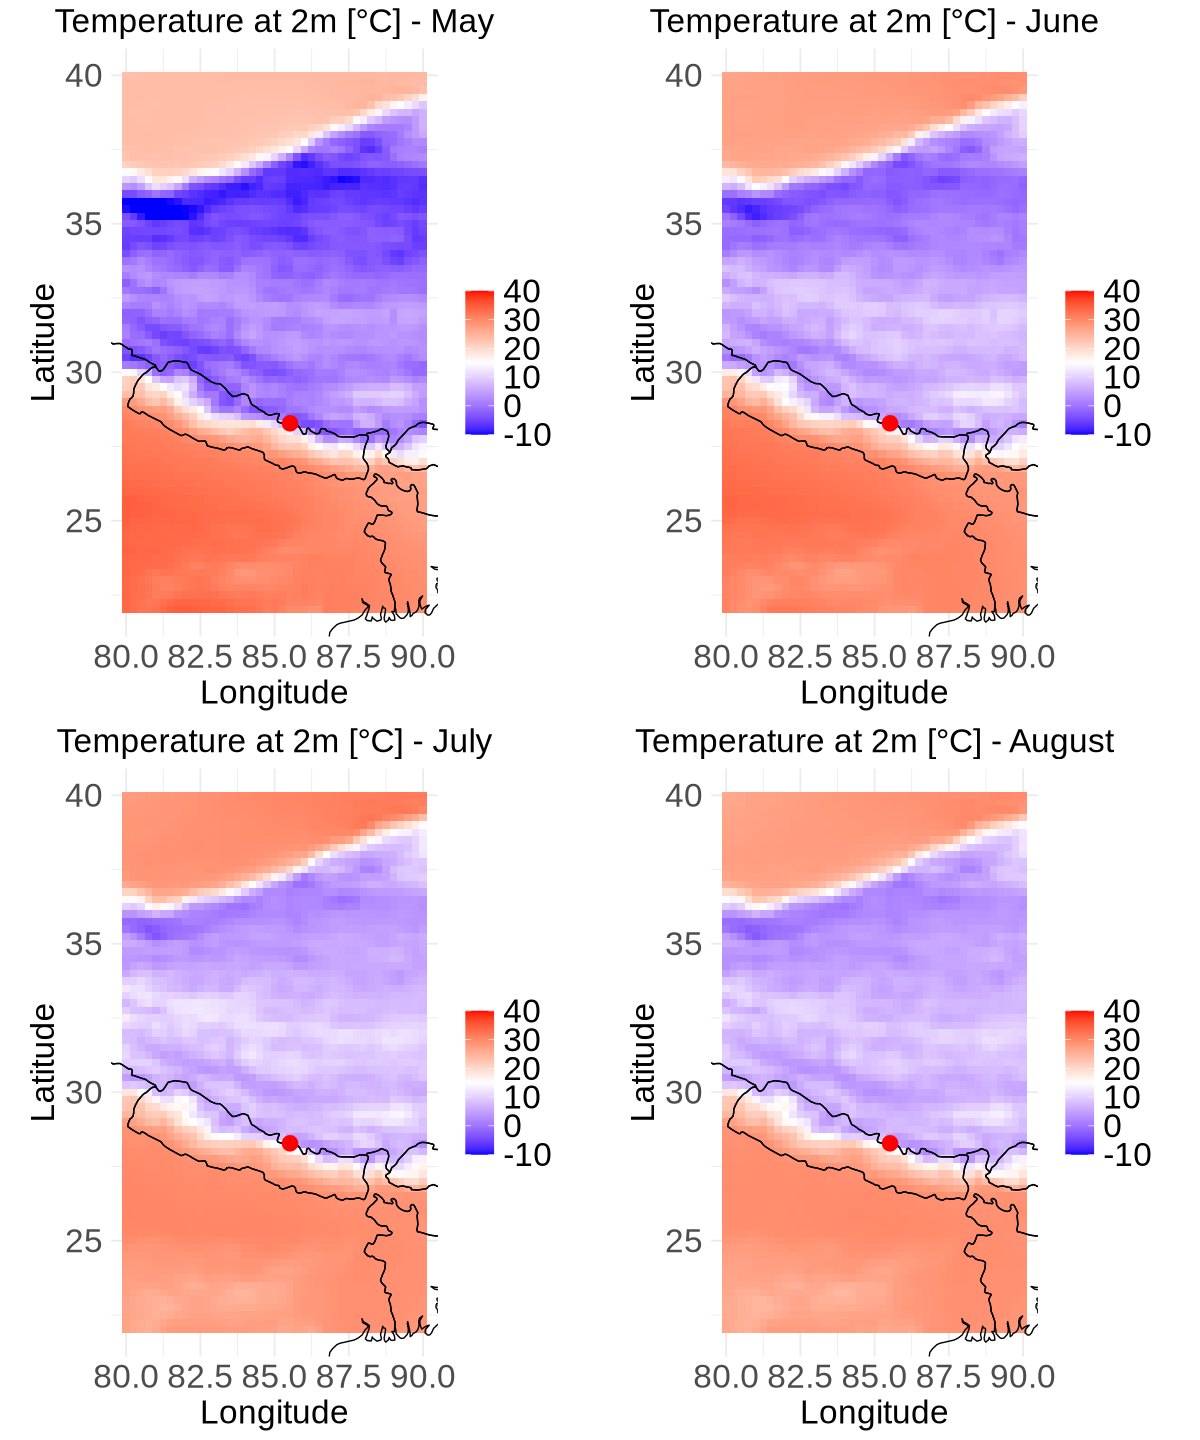

In [46]:
# creating maps
p1=mapping_dataframe(df_climatology_month,index_month=5, c(-10,40),"mean_t2m","Temperature at 2m [°C]")
p2=mapping_dataframe(df_climatology_month,index_month=6, c(-10,40),"mean_t2m","Temperature at 2m [°C]")
p3=mapping_dataframe(df_climatology_month,index_month=7,c(-10,40),"mean_t2m","Temperature at 2m [°C]")
p4=mapping_dataframe(df_climatology_month,index_month=8, c(-10,40),"mean_t2m","Temperature at 2m [°C]")

# Determine figure size
options(repr.plot.width =10, repr.plot.height = 12) 
p_total=grid.arrange(p1, p2, p3, p4, ncol = 2, nrow = 2)

We have displayed the temperature maps from May to August to examine the seasonal evolution. A strong temperature gradient can be observed, mainly due to differences in elevation between the mountains and the surrounding plains.

### 5.2.2. Monthly anomaly maps with 2026
[Go back to the "Table of contents"](#Table-of-contents)

We will now compare the temperature anomalies from May to August 2026 with the corresponding monthly climatology. To do this, we will extract the 2026 data and calculate the difference between the 2026 temperatures and the monthly climatology calculated over the 2000–2026 period. This will allow us to identify where and during which months temperatures in 2026 were significantly different from the long-term average.

In [47]:
# Monthly mean for 2026
df_month_2026 <- df_climatology %>% 
  filter(year == 2026) %>%
  group_by(Longitude, Latitude, month) %>%
  summarise(
      mean_t2m  = mean(t2m,  na.rm = TRUE),
    .groups = "drop"
  )

In [48]:
# Anomaly: month 2026 - climatological mean
df_anomaly_2026 <- df_climatology_month %>%
  left_join(
    df_month_2026,
    by = c("Longitude", "Latitude", "month"),
    suffix = c("_clim", "_2026")
  ) %>%
  mutate(
    anomaly_t2m  = mean_t2m_2026  - mean_t2m_clim,
  )

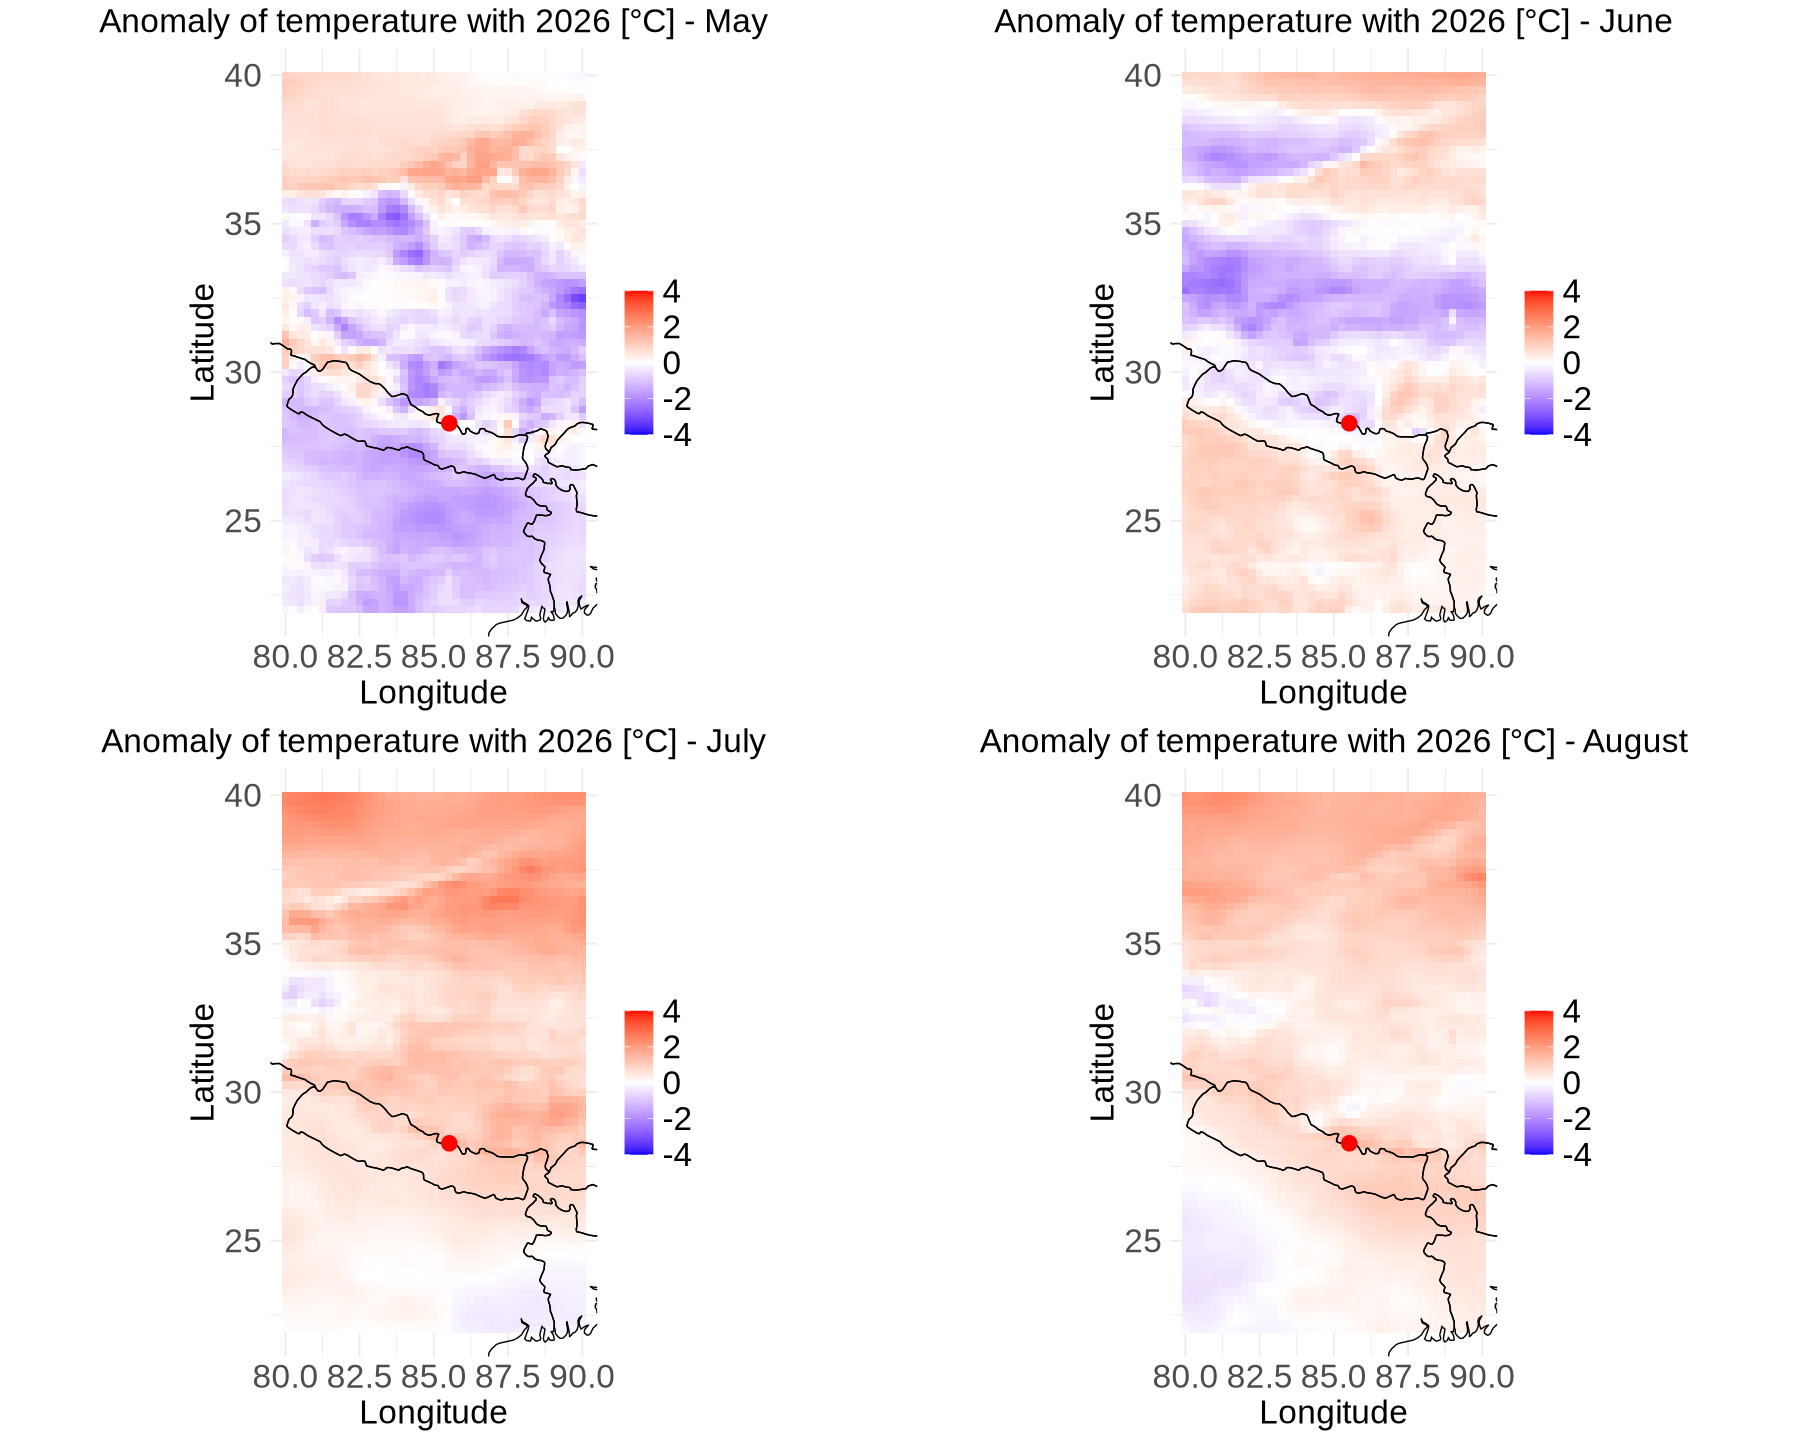

In [49]:
# creating maps
p1=mapping_dataframe(df_anomaly_2026,index_month=5, c(-4,4),"anomaly_t2m","Anomaly of temperature with 2026 [°C]")
p2=mapping_dataframe(df_anomaly_2026,index_month=6, c(-4,4),"anomaly_t2m","Anomaly of temperature with 2026 [°C]")
p3=mapping_dataframe(df_anomaly_2026,index_month=7, c(-4,4),"anomaly_t2m","Anomaly of temperature with 2026 [°C]")
p4=mapping_dataframe(df_anomaly_2026,index_month=8, c(-4,4),"anomaly_t2m","Anomaly of temperature with 2026 [°C]")

# Determine figure size
options(repr.plot.width =15, repr.plot.height = 12) 
p_total=grid.arrange(p1, p2, p3, p4, ncol = 2, nrow = 2)

We can observe higher temperatures in 2026 during July and August compared with the climatological average. In contrast, May shows lower temperatures than the average.

## 5.3. Temperature anomaly at glacier point
[Go back to the "Table of contents"](#Table-of-contents)

We will now focus on the temperature conditions at the glacier location and examine how they have evolved over the years. In particular, we will look at the temperature anomalies observed in August, the month of the glacier collapse.

By comparing August temperatures with the long-term climatological average, we can identify whether recent years have experienced unusually warm or cool conditions at this location. This allows us to place the 2026 event in a longer-term climate context and investigate whether the period around the glacier collapse was characterised by unusually high temperatures.



In [50]:
# Define the glacier collapse coordinates
glacier_lon <- 85.525
glacier_lat <- 28.285

In [51]:
# Select the nearest grid point to the glacier collapse
df_glacier <- df_climatology %>%
  mutate(
    distance = sqrt((Longitude - glacier_lon)^2 + (Latitude - glacier_lat)^2)
  ) %>%
  group_by(year, month) %>%
  slice_min(distance, n = 1) %>%
  ungroup()

In [52]:
# Select August data
df_august <- df_glacier %>%
  filter(month == 8)

In [53]:
# Calculate the climatological mean temperature for August
clim_t2m <- mean(df_august$t2m, na.rm = TRUE)

# Calculate the August temperature anomalies
df_august <- df_august %>%
  mutate(
    anomaly_t2m = t2m - clim_t2m
  )

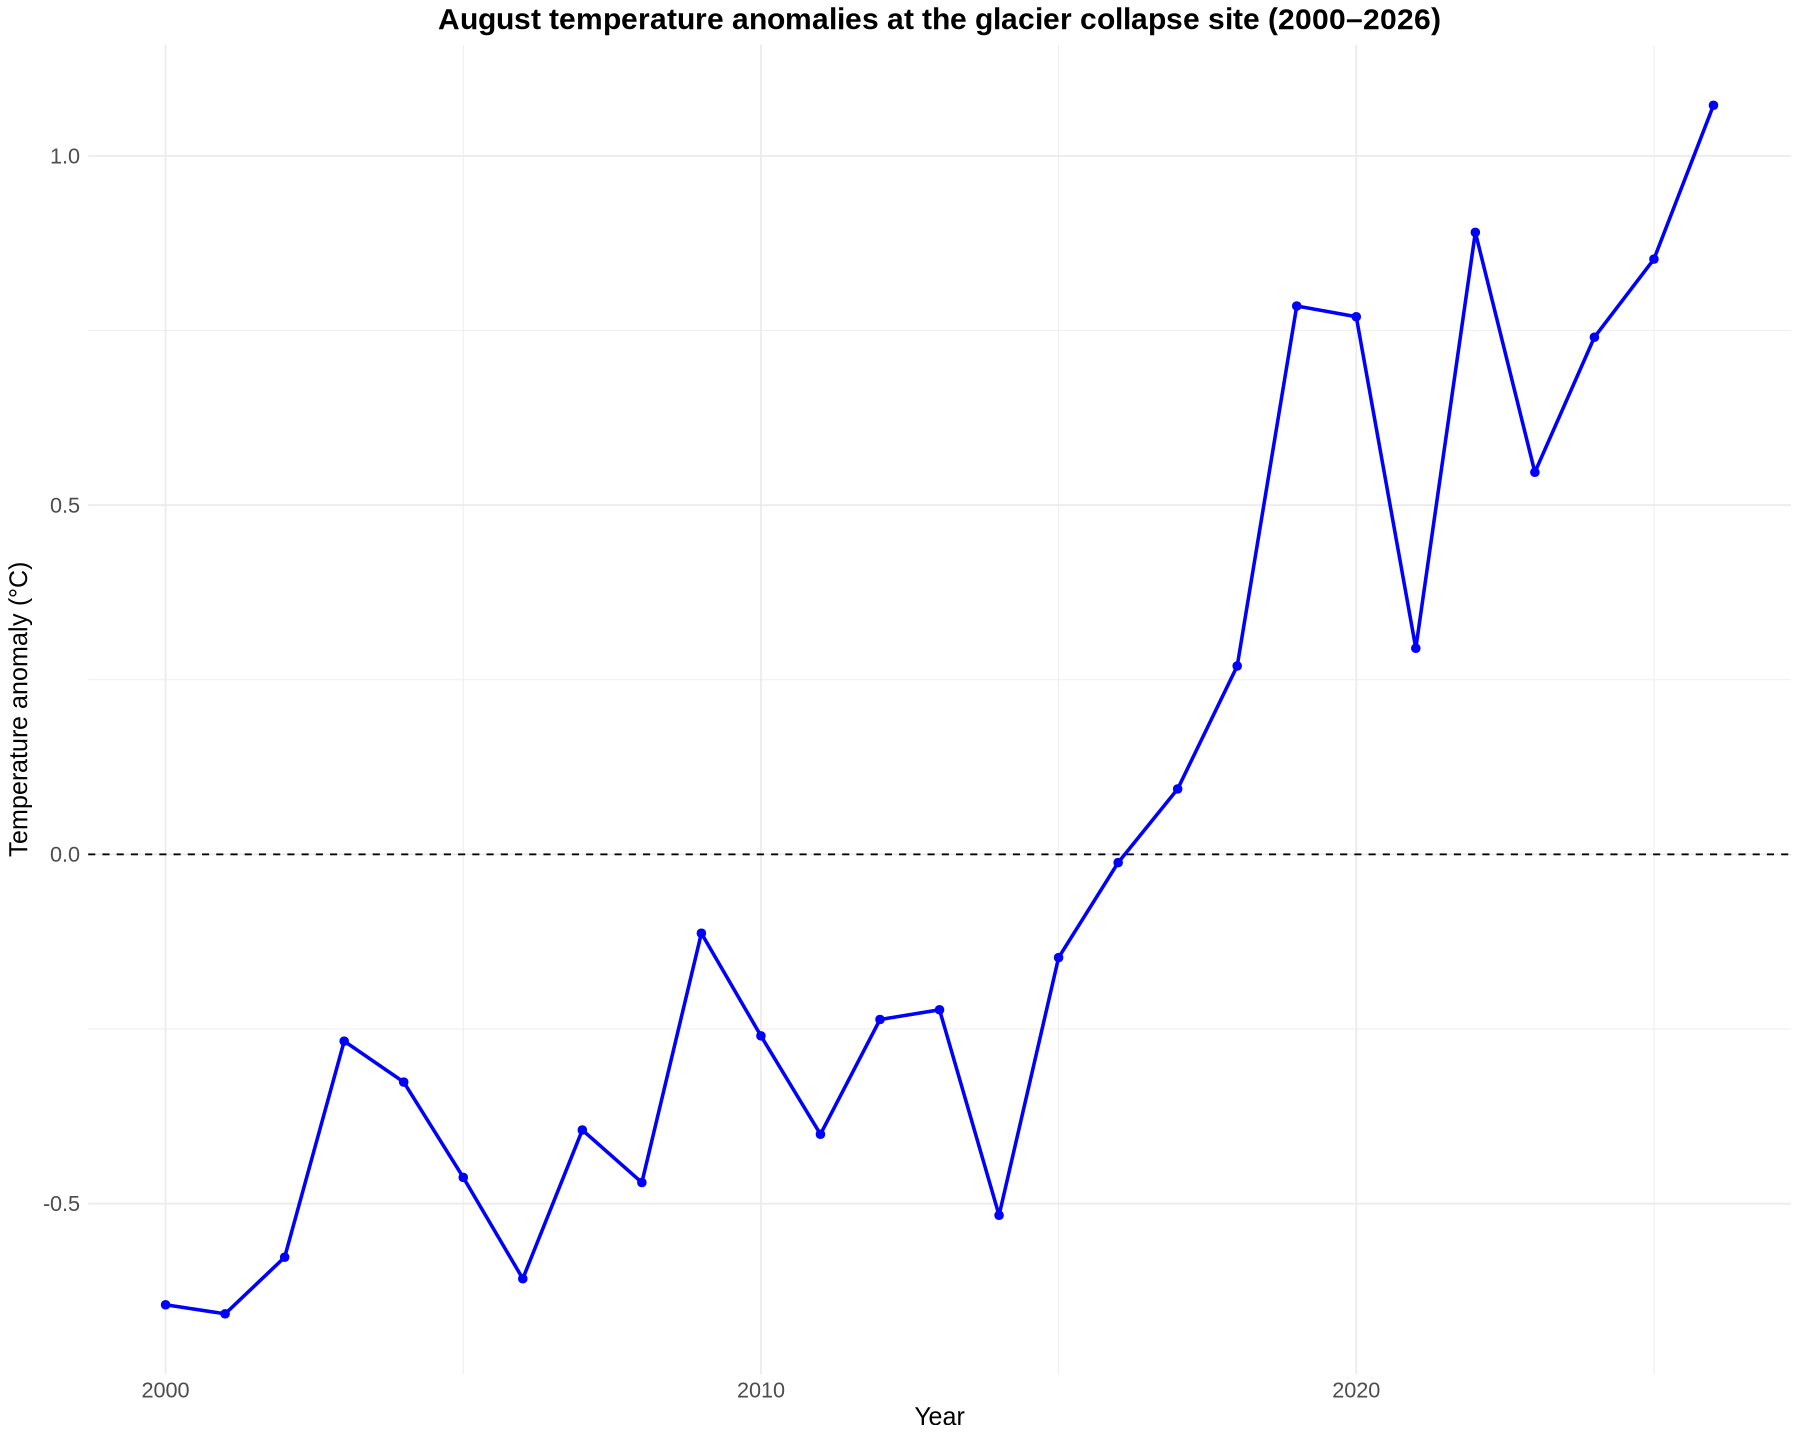

In [54]:
# Plot the August temperature anomalies
ggplot(df_august, aes(x = year, y = anomaly_t2m)) +

  # Air temperature anomaly
  geom_line(color = "blue", linewidth = 1) +
  geom_point(color = "blue", size = 2) +

  # Zero line = climatological average
  geom_hline(yintercept = 0, linetype = "dashed") +

  # Labels
  labs(
    title = "August temperature anomalies at the glacier collapse site (2000–2026)",
    x = "Year",
    y = "Temperature anomaly (°C)"
  ) +

  # Plot style
  theme_minimal() +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    axis.title = element_text(size = 15),
    axis.text = element_text(size = 13)
  )

The August temperature anomalies show a clear shift towards warmer conditions in recent years. 2026 recorded the highest anomaly in the 2000–2026 period, indicating unusually warm conditions at the glacier site before the collapse.

This case study shows how Earth Observation can help assess ecosystem health and the impacts of extreme events. Sentinel-2 imagery revealed major changes in the river and surrounding landscape after the flash flood, while temperature data showed increasingly warm conditions at the glacier site.

By combining satellite imagery with long-term environmental data, we can better monitor ecosystem changes and understand the vulnerability of mountain environments to extreme events and climate change.

# 6. Exercises
[Go back to the "Table of contents"](#Table-of-contents)

Here is a set of exercises we propose for you to go further into the analysis. There are 3 levels depending on how much R code you need to write to answer the questions.

**Beginners** :
- In [Section 5.1](#5.1.-Exploring-the-dataset), we have plotted the map of the temperature in May 2000. Try exploring the dataset by visualizing other dates!

**Intermediate** :
- In [Section 5.3.](#5.3.-Temperature-anomaly-at-glacier-point), you could download hourly temperature data from ERA5 and try to create time series plot, showing the temperature at Glacier Point over the last few days.

**Experts** :
- In [Section 4.](#4.-Visualising-the-Flood-with-Sentinel-2-data), we plotted Sentinel-2 images, "you can try to 
calculate the NDVI (Normalized Difference Vegetation Index), an indicator of vegetation presence and vigour. You could compare before and after the flood. NDVI=(B8-B4)/(B8+B4). B8 and B4 correspond to the Near-Infrared and Red bands, respectively. The Near-Infrared band is not available in the data folder. It is possible to download the products from the WEkEO [Data Viewer](https://data.wekeo.copernicus.eu/data?view=viewer&objects=W10%3D&zoom=0) Data Viewer and, therefore, access the Near-Infrared band.

# 7. Conclusion
[Go back to the "Table of contents"](#Table-of-contents)

<div class="alert alert-block alert-success">
<b>Congratulations!</b> You have successfully completed the tutorial on using WEkEO products to evaluate the impact of flash flooding in Nepal on the ecosystem health. Throughout this tutorial, we have explained the basic tools necessary to access and visualize model data, generate different types of plots.
<br><br>

In this tutorial, you acquired all the information you need to:
 

* Download WEkEO products.
* Access NetCDF datasets.
* Use satellite data.
* Navigate through the different variables, dimensions and attributes of a NetCDF file.
* Select data subsets within a NetCDF file.
* Create timeseries.
* Plot maps of any variable.
 
We sincerely hope that you have enjoyed the tutorial and found useful information in it. Please keep in mind that the tutorial has a progressive difficulty, moving quickly from basic elements to intermediate levels. Our intention is for all users to find useful information tailored to their level.
 
We understand that, for a user without prior knowledge, fully understanding all the procedures in the tutorial may be a challenge that requires some effort. However, we encourage everyone to take on the challenge as this is just the beginning of a journey towards a new understanding of ecosystem health.

This tutorial is over but we'd love to hear from you about how we could improve it (topics, tools, storytelling, format, speed, etc). If you have any question, do not hesitate to contact us via the WEkEO chatbot in the bottom-right corner of any [WEkEO](https://www.wekeo.eu/) page.

Credit: This tutorial was created by [NOVELTIS](https://www.noveltis.fr/) under Contract with Mercator Ocean for WEkEO.
</div>

 